# Assemble a cantilever from Hermite elements; validate its first three modes.

Run in a Python environment with OneSimulation 0.2.0, NumPy, SciPy and Matplotlib. Change the input data and rerun to compare with the saved reference output.

2 elements [Hz] [  8.386   52.9742 179.1685]
16 elements [Hz] [  8.3819  52.5288 147.0871]
analytical [Hz] [  8.3819  52.5285 147.0813]


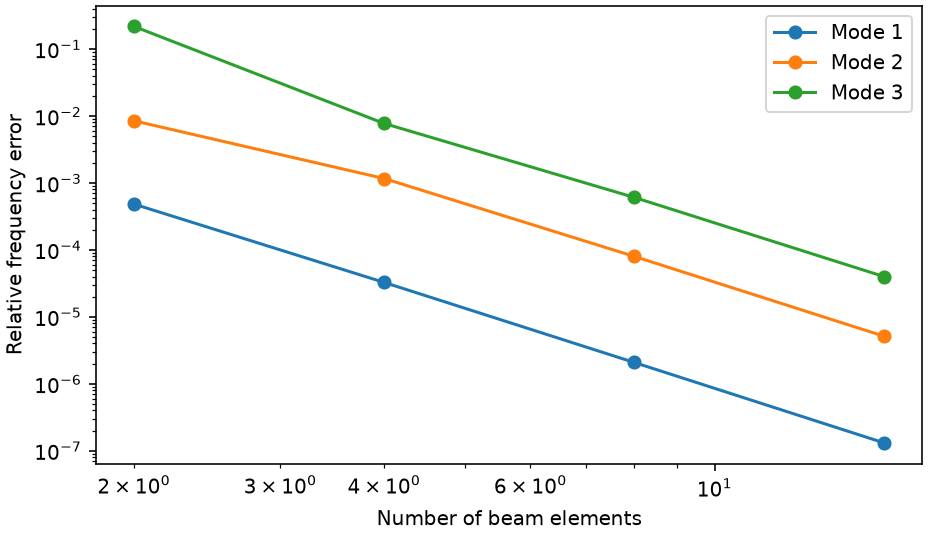

In [1]:
"""Assemble a cantilever from Hermite elements; validate its first three modes."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.linear import SparseSymmetricEigenSolver

length, width, depth = 1.0, 0.03, 0.01  # m
E, density = 210e9, 7800.0
area, inertia = width*depth, width*depth**3/12

def beam_frequencies(elements):
    h = length/elements
    k = E*inertia/h**3*np.array([[12,6*h,-12,6*h],[6*h,4*h*h,-6*h,2*h*h],
                                 [-12,-6*h,12,-6*h],[6*h,2*h*h,-6*h,4*h*h]])
    m = density*area*h/420*np.array([[156,22*h,54,-13*h],[22*h,4*h*h,13*h,-3*h*h],
                                    [54,13*h,156,-22*h],[-13*h,-3*h*h,-22*h,4*h*h]])
    size = 2*(elements+1)
    mass, stiffness = np.zeros((size,size)), np.zeros((size,size))
    for element in range(elements):
        dofs = np.arange(2*element,2*element+4)
        mass[np.ix_(dofs,dofs)] += m
        stiffness[np.ix_(dofs,dofs)] += k
    values, modes = SparseSymmetricEigenSolver()(mass[2:,2:], stiffness[2:,2:],
                                                 mode_count=3, target=0.0)
    assert np.allclose(modes.T @ mass[2:,2:] @ modes, np.eye(3), atol=1e-8)
    return np.sqrt(values)/(2*np.pi)

beta = np.array([1.875104069,4.694091133,7.854757438])
exact = beta**2*np.sqrt(E*inertia/(density*area))/(2*np.pi*length**2)
counts = [2, 4, 8, 16]
frequencies = np.array([beam_frequencies(count) for count in counts])
print("2 elements [Hz]", np.round(frequencies[0], 4))
print("16 elements [Hz]", np.round(frequencies[-1], 4))
print("analytical [Hz]", np.round(exact, 4))
fig, ax = plt.subplots(figsize=(6.4,3.7), layout="constrained")
for mode in range(3):
    ax.loglog(counts, abs(frequencies[:,mode]/exact[mode]-1), "o-", label=f"Mode {mode+1}")
ax.set(xlabel="Number of beam elements", ylabel="Relative frequency error")
ax.legend()
plt.show()
